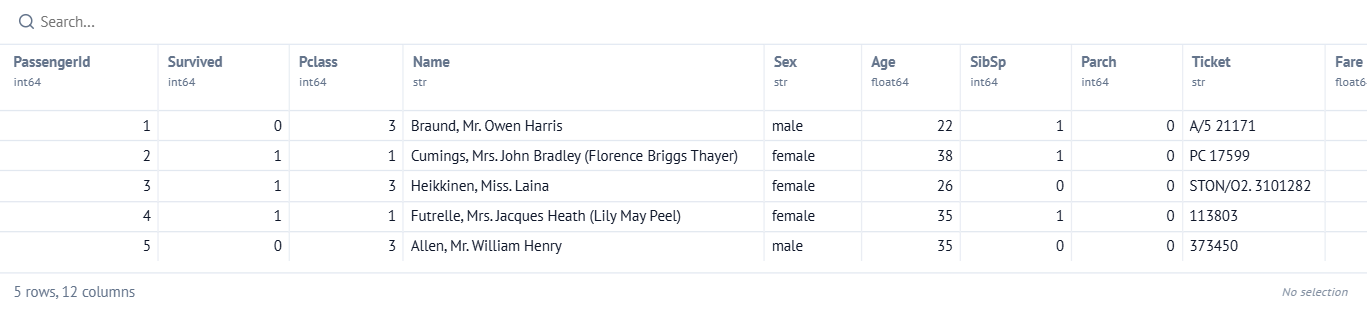

In [ ]:
import pandas as pd

df = pd.read_csv("titanic/train.csv")
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


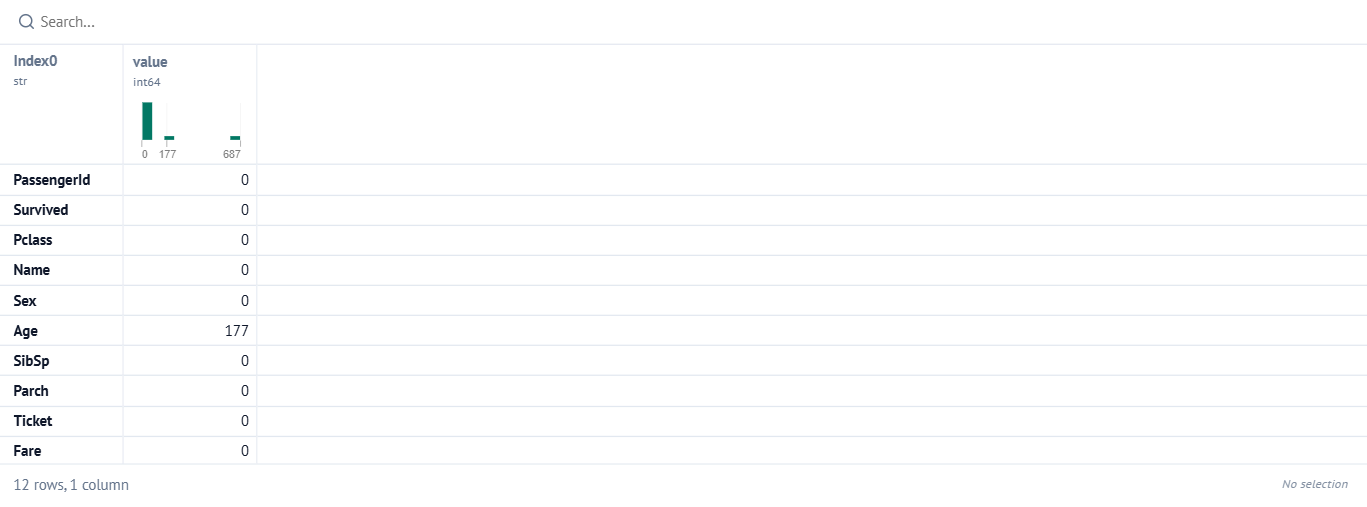

In [ ]:
df.info()
df.isnull().sum()

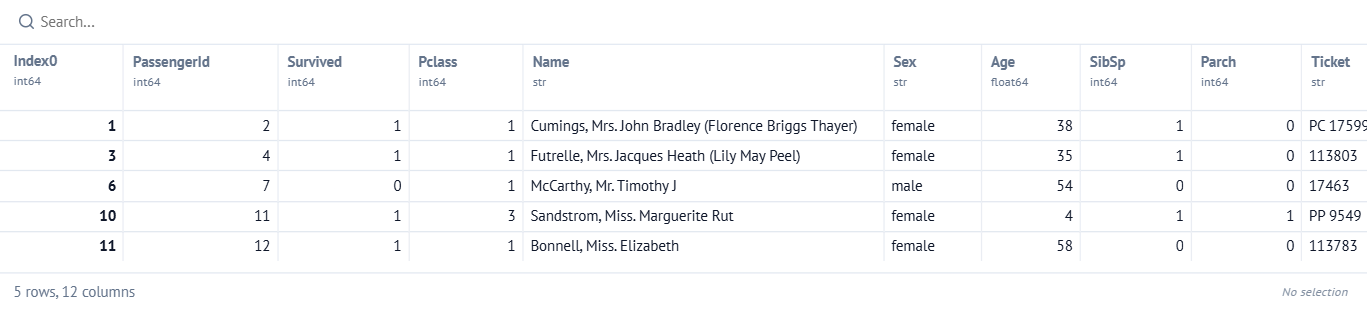

In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].median())
df_clean = df.drop(columns=['Cabin'])
df_clean = df.dropna()
df_clean.head()

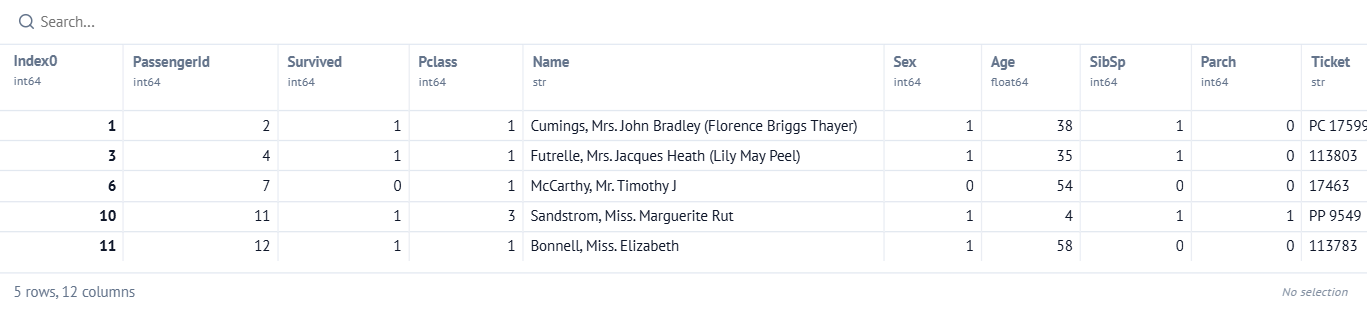

In [ ]:
df_clean['Sex'] = df_clean['Sex'].map( {'female': 1, 'male': 0} )
df_clean['Embarked'] = df_clean['Embarked'].map( { 'Q':0, 'C': 1, 'S':2 } )
df_clean.head()

In [ ]:
data = df_clean[['Survived','Pclass','Sex','Age','SibSp','Parch','Fare','Embarked']]
X = data.drop('Survived', axis=1)
Y = data['Survived']

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

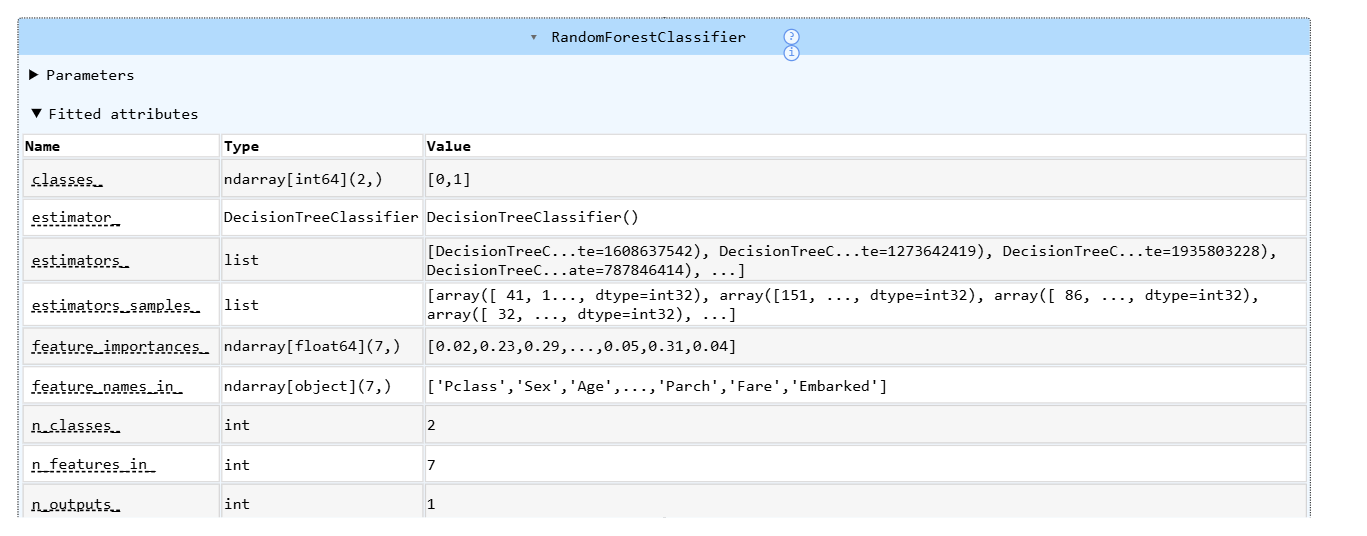

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

log_model = LogisticRegression(max_iter=1000)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

log_model.fit(X_train, Y_train)
rf_model.fit(X_train, Y_train)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

Y_pred_log = log_model.predict(X_test)
Y_pred_rf = rf_model.predict(X_test)

print('Accuracy (Logistic):', accuracy_score(Y_test, Y_pred_log))
print('AccuracY (Random Forest):', accuracy_score(Y_test, Y_pred_rf))
print(classification_report(Y_test, Y_pred_rf))

Accuracy (Logistic): 0.8292682926829268
AccuracY (Random Forest): 0.8048780487804879
              precision    recall  f1-score   support

           0       0.50      0.75      0.60         8
           1       0.93      0.82      0.87        33

    accuracy                           0.80        41
   macro avg       0.72      0.78      0.74        41
weighted avg       0.85      0.80      0.82        41



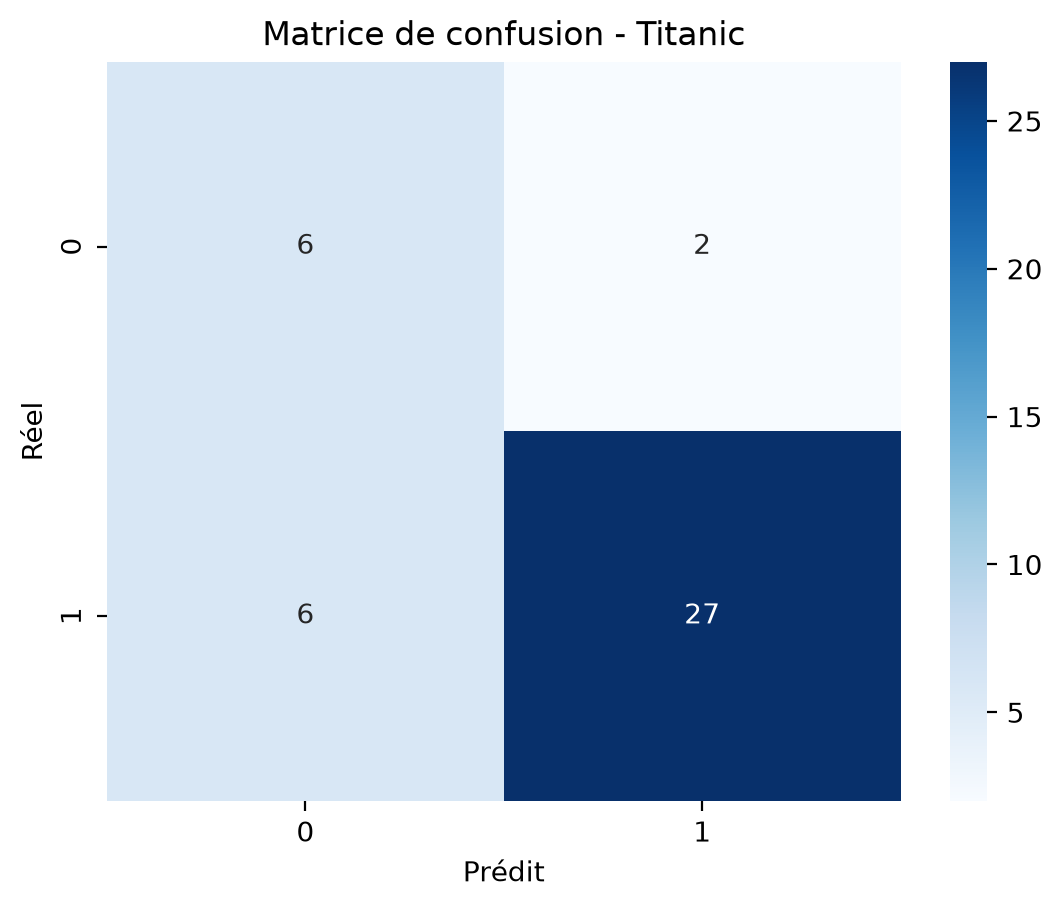

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(Y_test, Y_pred_rf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matrice de confusion - Titanic')
plt.xlabel('Prédit')
plt.ylabel('Réel')
plt.show()